# 05 — Regime models: baselines, logistic regression, LightGBM, SVM

*CRISP-DM phase 5 (modeling) · code: `run_models.py`, `src/sp500/models.py`*

Walk-forward evaluation 1980–2021: each year is predicted by models trained only on earlier years (21-day gap). Targets: bear / stressed in 5 and 21 days (main + robustness labels). The 2022+ holdout is **not** used here.

← previous: [`04_statistical_tests.ipynb`](04_statistical_tests.ipynb) · next: [`06_feature_groups.ipynb`](06_feature_groups.ipynb) →

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]   # project package + root scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 10})

In [2]:
def run_script(module, *args):
    """Run a project script's main() exactly as on the command line, then restore inline plots."""
    import importlib
    mod = importlib.import_module(module)
    old = sys.argv
    sys.argv = [f"{module}.py", *args]
    try:
        code = mod.main()
    finally:
        sys.argv = old
    get_ipython().run_line_magic("matplotlib", "inline")
    return code

## 1. Train and evaluate (≈ 2 min)

In [3]:
run_script("run_models")

[18:22:02] Walk-forward: features=main (13), train from 1962-01-01, test 1980-2021, gap 21 days


Model is not converging.  Current: 14987.480405529464 is not greater than 14987.516724753747. Delta is -0.036319224282124196


[18:22:05]       fold 1/42: test 1980 (train 4,209 rows up to 1979-12-31)


Model is not converging.  Current: 15787.245442648766 is not greater than 15787.273302953741. Delta is -0.02786030497554748


[18:22:06]       fold 2/42: test 1981 (train 4,462 rows up to 1980-12-31)


[18:22:08]       fold 3/42: test 1982 (train 4,715 rows up to 1981-12-31)


... (53 outputs left out)

[18:23:46] Done in 103s; 507,408 predictions


[18:23:48] wrote reports/model_results_main.md, .csv and docs/figures/model_timeline_main.png



PR-AUC (main targets):
label         bear        stressed       
horizon         5      21       5      21
method                                   
persistence  0.131  0.122    0.776  0.512
ma200_rule   0.299  0.261      NaN    NaN
hmm          0.277  0.280    0.749  0.531
logreg       0.361  0.293    0.930  0.661
lightgbm     0.358  0.340    0.927  0.648
svm          0.355  0.313    0.847  0.555

Onset PR-AUC (main targets):
label         bear        stressed       
horizon         5      21       5      21
method                                   
persistence  0.004  0.017    0.051  0.128
ma200_rule   0.004  0.018      NaN    NaN
hmm          0.006  0.044    0.149  0.191
logreg       0.005  0.032    0.282  0.260
lightgbm     0.003  0.014    0.278  0.265
svm          0.005  0.019    0.220  0.211


0

## 2. Results

**PR-AUC** ranks future regime days above normal ones (random = base rate). **Onset PR-AUC** looks only at days when the regime is not active yet: can the method predict a regime *starting*?

In [4]:
from run_models import METHOD_NAMES
m = pd.read_csv(ROOT / "reports" / "model_results_main.csv")
order = list(METHOD_NAMES)
for metric in ("pr_auc", "onset_pr_auc"):
    t = m.pivot_table(index="method", columns=["label", "horizon"], values=metric).reindex(order)
    t.index = t.index.map(METHOD_NAMES)
    display(Markdown(f"**{metric.replace('_', ' ').upper()}**"))
    display(t.style.format("{:.3f}").highlight_max(axis=0, color="#d7e8fb"))

**PR AUC**

**ONSET PR AUC**

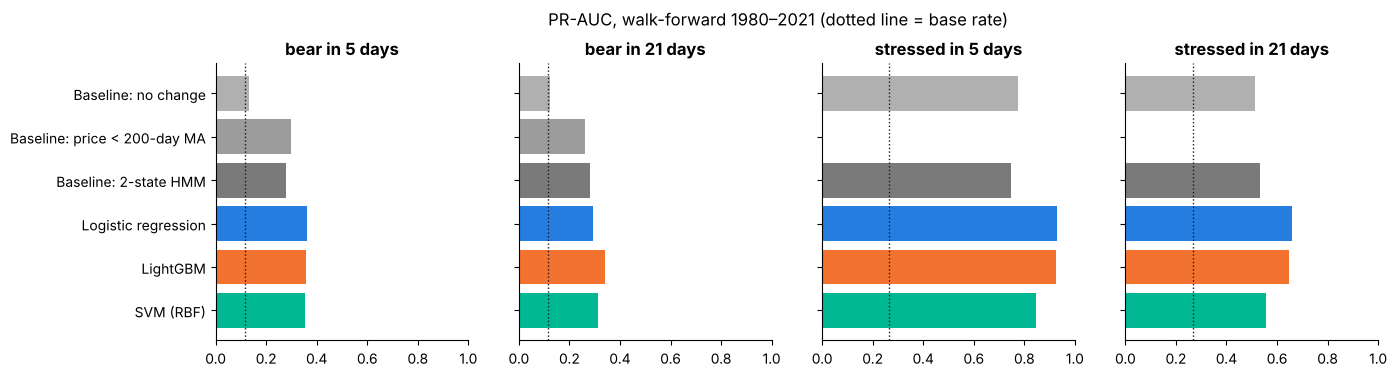

In [5]:
main = m[m.label.isin(["stressed", "bear"])]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
colors = {"persistence": "#b0b0b0", "ma200_rule": "#9c9c9c", "hmm": "#7a7a7a", "logreg": "#257de0", "lightgbm": "#f47230", "svm": "#00b894"}
for ax, ((label, h), g) in zip(axes, main.groupby(["label", "horizon"])):
    g = g.set_index("method").reindex(order).dropna(subset=["pr_auc"])
    ax.barh([METHOD_NAMES[i] for i in g.index], g["pr_auc"], color=[colors[i] for i in g.index])
    ax.axvline(g["base_rate"].iloc[0], color="#191919", ls=":", lw=1)
    ax.set_title(f"{label} in {h} days"); ax.set_xlim(0, 1); ax.spines[["top", "right"]].set_visible(False)
axes[0].invert_yaxis()
fig.suptitle("PR-AUC, walk-forward 1980–2021 (dotted line = base rate)", y=1.03)
plt.show()

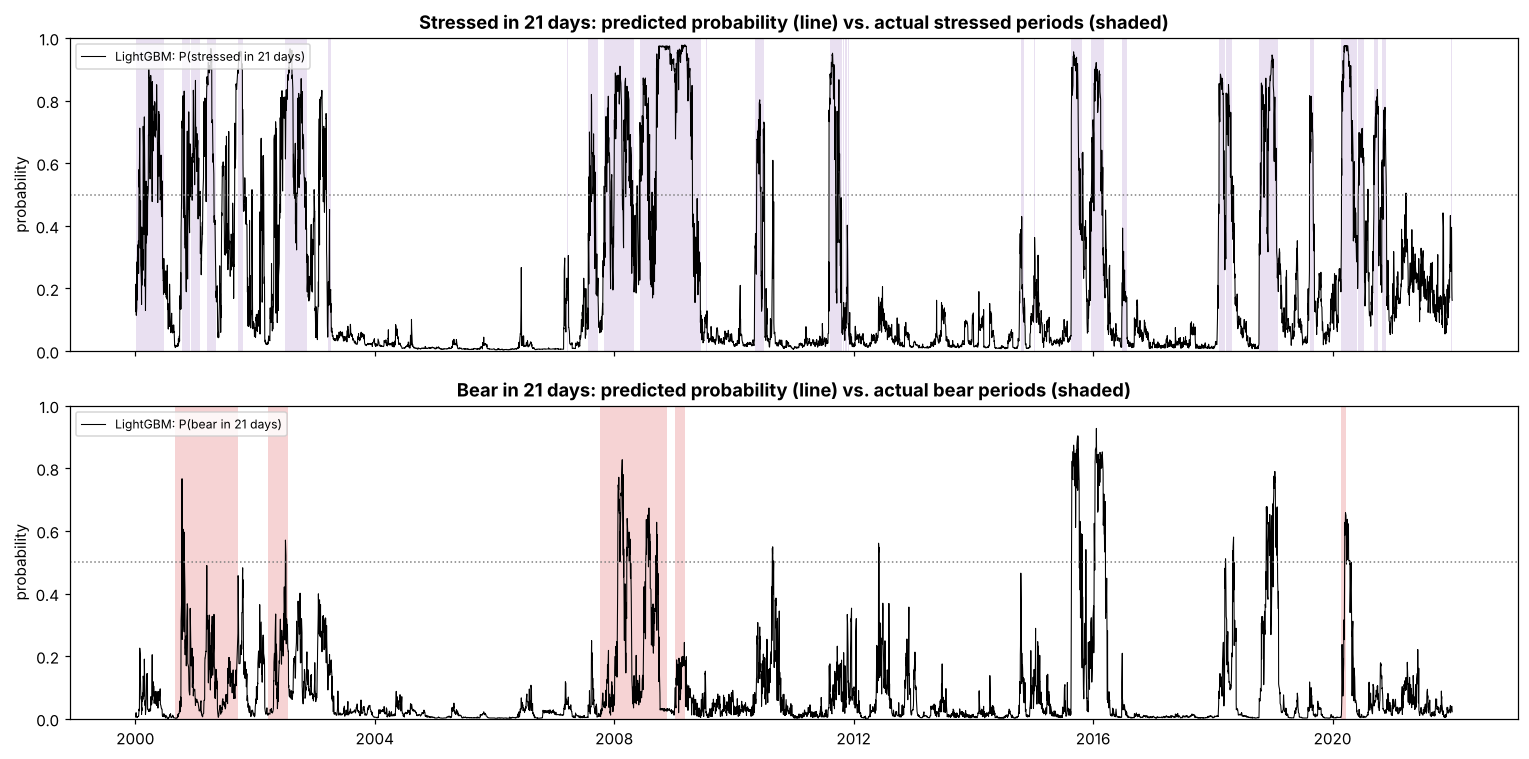

In [6]:
display(Image(ROOT / "docs" / "figures" / "model_timeline_main.png"))

Full report with Brier scores, signal flips and early-warning lead times: [`reports/model_results_main.md`](../reports/model_results_main.md).

**Result.** Short-term stress is clearly predictable (models beat every baseline); bear markets are recognized only after the fall has begun.